# Lab 7: Go-to-goal

Fayozbek Yusupov, ID 240061

The program is `Fixed_1x1_trajectory.qrs` from the lecture with my waypoints for "61" (in metres in TRIK, in cm here). The robot starts in the left end of the middle line of the 6, facing +x. The 6 is drawn as middle line, lower right side, bottom, left side, top. Then it goes down to (30, 10), up the flag of the 1 to (40, 20) and down the 1 to (40, -20).

Gains (the same in both programs): K_θ = 100 (`u = 100 * err`), K_v = 400 and v_max = 60 (`mov = min(400 * dist, 60) * cos(err)`), acceptance radius ε = 0.03 m. Only r and B are different: r = 0.028 m, B = 0.154 m in the simulator and r = 0.0375 m, B = 0.194 m on the real robot.

Upload `odometry_data_sim.txt` and `odometry_data_real.txt` in the next cell.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select BOTH txt files

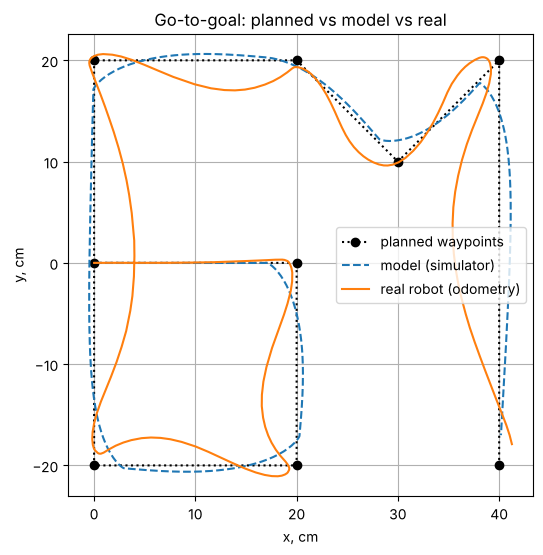

In [2]:
# Planned waypoints: copy them from your TRIK program
wp = np.array([[0, 0], [20, 0], [20, -20], [0, -20], [0, 20], [20, 20], [30, 10], [40, 20], [40, -20]])

x_s, y_s, t_s = np.loadtxt('odometry_data_sim.txt',  delimiter=',', unpack=True)
x_r, y_r, t_r = np.loadtxt('odometry_data_real.txt', delimiter=',', unpack=True)

# 1. Planned path vs simulated vs real
plt.figure(figsize=(6, 6))
plt.plot(wp[:, 0], wp[:, 1], 'k:o', label='planned waypoints')
plt.plot(x_s, y_s, '--', label='model (simulator)')
plt.plot(x_r, y_r,       label='real robot (odometry)')
plt.axis('equal'); plt.grid(True); plt.legend()
plt.xlabel('x, cm'); plt.ylabel('y, cm')
plt.title('Go-to-goal: planned vs model vs real')
plt.show()

In both runs the robot drew the 61. The simulator keeps about 2 cm from every corner (this is ε) and its lines are straight. The real robot switches to the next point at the same 3 cm, but it rolls on a little and passes 0.1–2.4 cm from the corners; its straight pieces are wavy: after every turn it swings about 30° past the direction to the next point and comes back, so it is up to 3–5 cm off the line. It also drives faster, so the real run took 9.7 s against 18.4 s.

In [3]:
# 2. How close did each run get to each waypoint?
def waypoint_miss(x, y, wp):
    return np.array([np.min(np.hypot(x - px, y - py)) for px, py in wp])

miss_s = waypoint_miss(x_s, y_s, wp)
miss_r = waypoint_miss(x_r, y_r, wp)
for i, (ms, mr) in enumerate(zip(miss_s, miss_r)):
    print(f'Waypoint {i} {tuple(wp[i])}: sim {ms:5.1f} cm | real {mr:5.1f} cm')

Waypoint 0 (np.int64(0), np.int64(0)): sim   0.0 cm | real   0.0 cm
Waypoint 1 (np.int64(20), np.int64(0)): sim   2.0 cm | real   0.7 cm
Waypoint 2 (np.int64(20), np.int64(-20)): sim   1.9 cm | real   0.8 cm
Waypoint 3 (np.int64(0), np.int64(-20)): sim   2.0 cm | real   1.3 cm
Waypoint 4 (np.int64(0), np.int64(20)): sim   2.0 cm | real   0.4 cm
Waypoint 5 (np.int64(20), np.int64(20)): sim   0.6 cm | real   0.7 cm
Waypoint 6 (np.int64(30), np.int64(10)): sim   2.1 cm | real   0.1 cm
Waypoint 7 (np.int64(40), np.int64(20)): sim   2.9 cm | real   0.9 cm
Waypoint 8 (np.int64(40), np.int64(-20)): sim   3.0 cm | real   2.4 cm


In [4]:
# 3. Run time
print(f'Run time: sim {(t_s[-1]-t_s[0])/1000:.1f} s | real {(t_r[-1]-t_r[0])/1000:.1f} s')

Run time: sim 18.4 s | real 9.7 s


## Measured end point

Before the run I put coin 1 next to the left wheel and coin 2 next to the right wheel, where they touch the floor. After the run I did the same with coins 3 and 4 and measured the distances between the coins with a tape: 1–2 = 22 cm, 1–3 = 66 cm, 1–4 = 41 cm, 2–3 = 66 cm, 2–4 = 44 cm. With x along the start direction and y to the left, coin 1 is at (0, 11) and coin 2 at (0, -11). From the two distances to coins 1 and 2 each end coin is found as the crossing of two circles: coin 3 is at (65, 0) and coin 4 at (41, 6). The robot centre is the middle between them.

In [5]:
d12, d13, d14, d23, d24 = 22, 66, 41, 66, 44

def coin(a, b):
    y = (b**2 - a**2) / (2 * d12)
    x = np.sqrt(a**2 - (y - d12 / 2)**2)
    return x, y

x3, y3 = coin(d13, d23)
x4, y4 = coin(d14, d24)
x_tape, y_tape = (x3 + x4) / 2, (y3 + y4) / 2

print(f'Coin 3: ({x3:.1f}, {y3:.1f}) cm, coin 4: ({x4:.1f}, {y4:.1f}) cm')
print(f'Last waypoint:        x = {wp[-1, 0]:.1f} cm, y = {wp[-1, 1]:.1f} cm')
print(f'Odometry (last line): x = {x_r[-1]:.1f} cm, y = {y_r[-1]:.1f} cm')
print(f'Tape:                 x = {x_tape:.1f} cm, y = {y_tape:.1f} cm')
print(f'Tape - odometry: {np.hypot(x_r[-1] - x_tape, y_r[-1] - y_tape):.1f} cm, '
      f'tape - last waypoint: {np.hypot(wp[-1, 0] - x_tape, wp[-1, 1] - y_tape):.1f} cm')

Coin 3: (65.1, 0.0) cm, coin 4: (40.7, 5.8) cm
Last waypoint:        x = 40.0 cm, y = -20.0 cm
Odometry (last line): x = 41.3 cm, y = -17.9 cm
Tape:                 x = 52.9 cm, y = 2.9 cm
Tape - odometry: 23.8 cm, tape - last waypoint: 26.3 cm


## Conclusions

In the simulator every corner is cut by about 2 cm, and this comes from the acceptance radius ε = 0.03 m: the waypoint counts as reached 3 cm before it and the robot turns to the next one at once. The real robot switches at the same 3 cm but reacts later and rolls on, so it passes 0.1–2.4 cm from the corners, and no waypoint is overshot by its odometry (real miss 0.1–2.4 cm, simulator 0.6–3.0 cm). On the real robot the heading overshoots after every turn by about 30° and the straight pieces come out wavy, up to 3–5 cm off the line; this is K_θ = 100, which is a bit too high for the real robot, because its motors answer with a delay (Lab 5) and one pass of the loop takes about 45 ms instead of 10 ms in the simulator. The real run is twice as fast (9.7 s against 18.4 s) because the real wheels are bigger and the real motors faster, so the same power gives a higher speed. The remaining gap is a localization problem, not a control problem: the controller thinks it finished at (41, -18), 2.4 cm from the last waypoint, but the tape shows the robot at (53, 3), 24 cm away from where the odometry says. The controller did its job on the position it was given; the position itself was wrong, most likely because of wheel slip in the fast turns, which the encoders cannot see, like in Lab 6.